# Challenge 01 — VQE: Ground-State Energy of the H₂ Molecule
**Qiskit Fall Fest 2026 · Team Cdevi Code · Intermediate**

## Goal
Find the **lowest possible energy** (the *ground-state energy*) of a hydrogen molecule, H₂, using the
**Variational Quantum Eigensolver (VQE)**, and prove the answer is right by comparing it with an
exact classical calculation.

## Why does this matter?
The ground-state energy of a molecule decides its shape, how strongly its atoms are bound and how it
reacts. Computing it exactly on a classical computer gets exponentially expensive as molecules grow.
Quantum computers may handle this better because a register of qubits can naturally represent the
quantum state of electrons.

## Roadmap of this notebook
| Phase | What we do | Output |
|---|---|---|
| **1** | Define H₂ in PySCF → build its Hamiltonian → map to qubits → **exact classical answer** | the reference energy |
| 2 | Build the ansatz (parameterised quantum circuit) | a circuit with tunable angles |
| 3 | Run VQE (quantum circuit + classical optimizer) | VQE energy |
| 4 | Compare VQE vs exact, analyse error, discuss | verification and plots |

> **Units:** energies are in **Hartree (Ha)**, the natural unit of quantum chemistry
> (1 Ha ≈ 27.211 eV ≈ 627.5 kcal/mol). *Chemical accuracy* is a target error of
> **1.6 mHa** (= 1 kcal/mol); below it, a computed energy is accurate enough to predict chemistry.

## 0. Setup: imports and versions
Qiskit's API changes between releases, so we **print every library version**. Anyone re-running this
notebook can then check they have the same environment (see `requirements.txt`).

| Library | Role in this notebook |
|---|---|
| `pyscf` | Classical quantum-chemistry engine: computes the integrals that define the H₂ Hamiltonian |
| `qiskit_nature` | Bridges chemistry and Qiskit: turns PySCF output into a fermionic Hamiltonian and maps it onto qubits |
| `qiskit` | Core quantum-circuit and operator library (`SparsePauliOp`) |
| `qiskit_algorithms` | Ready-made algorithms: `NumPyMinimumEigensolver` (exact) and later `VQE` |
| `numpy` | Linear algebra for our independent cross-check |

In [1]:
import numpy as np

import pyscf
import qiskit
import qiskit_nature
import qiskit_algorithms

# Chemistry -> Qiskit bridge
from qiskit_nature.units import DistanceUnit                         # lets us say "Angstrom" explicitly
from qiskit_nature.second_q.drivers import PySCFDriver               # runs PySCF for us
from qiskit_nature.second_q.mappers import JordanWignerMapper        # fermions -> qubits
from qiskit_nature.second_q.algorithms import GroundStateEigensolver # chemistry-aware solver wrapper

# Exact (classical) eigensolver used as our ground truth
from qiskit_algorithms import NumPyMinimumEigensolver

# Independent cross-check with PySCF's own Full Configuration Interaction (FCI) solver
from pyscf import gto, scf, fci

print(f"qiskit            {qiskit.__version__}")
print(f"qiskit-nature     {qiskit_nature.__version__}")
print(f"qiskit-algorithms {qiskit_algorithms.__version__}")
print(f"pyscf             {pyscf.__version__}")
print(f"numpy             {np.__version__}")

qiskit            2.2.3
qiskit-nature     0.8.0
qiskit-algorithms 0.4.0
pyscf             2.15.0
numpy             2.2.6


## 1. Define the H₂ molecule with PySCF

To describe a molecule we must choose four things:

1. **Geometry**: where the nuclei sit. H₂ has two hydrogen nuclei on the z-axis, **0.735 Å** apart.
   That is close to H₂'s experimental equilibrium bond length (≈ 0.741 Å), the distance where the
   molecule is most stable.
2. **Charge = 0**: a neutral molecule, so 2 protons and **2 electrons**.
3. **Spin = 0**: PySCF's `spin` is 2S, the number of unpaired electrons. Both electrons are paired
   (one spin-up ↑, one spin-down ↓), which is the *singlet* ground state.
4. **Basis set = STO-3G**: electrons live in *orbitals*, and a basis set is the menu of mathematical
   functions used to build them. STO-3G is the smallest standard basis: **one 1s function per H atom**.
   Two atoms give 2 *spatial orbitals*, which combine into
   - a **bonding** orbital σg (lower energy, electrons pulled between the nuclei), and
   - an **antibonding** orbital σu* (higher energy).

**Behind the scenes, the `PySCFDriver`:**
- runs a **Hartree–Fock (HF)** calculation, a mean-field approximation in which each electron feels
  only the *average* repulsion of the others;
- uses the HF molecular orbitals to compute the **one- and two-electron integrals**. These numbers are
  exactly what the Hamiltonian needs.

HF misses *electron correlation* (electrons actively avoiding each other). The gap between the HF
energy and the exact energy is the **correlation energy**, and recovering it is the whole point of VQE.

In [2]:
# --- Molecule specification -------------------------------------------------
BOND_LENGTH = 0.735  # Angstrom, close to the H2 equilibrium bond length

driver = PySCFDriver(
    atom=f"H 0 0 0; H 0 0 {BOND_LENGTH}",  # "element x y z; element x y z"
    basis="sto3g",                          # minimal basis: one 1s orbital per H atom
    charge=0,                               # neutral molecule -> 2 electrons
    spin=0,                                 # 2S = 0 -> all electrons paired (singlet)
    unit=DistanceUnit.ANGSTROM,             # coordinates above are in Angstrom
)

# driver.run() calls PySCF (Hartree-Fock + integrals) and packages everything
# into an ElectronicStructureProblem object.
problem = driver.run()

n_spatial = problem.num_spatial_orbitals   # number of molecular orbitals
n_alpha, n_beta = problem.num_particles    # (# spin-up electrons, # spin-down electrons)
nuclear_repulsion = problem.hamiltonian.nuclear_repulsion_energy
hf_energy = problem.reference_energy       # Hartree-Fock total energy

print(f"Spatial orbitals          : {n_spatial}")
print(f"Spin orbitals (= qubits)  : {2 * n_spatial}")
print(f"Electrons (alpha, beta)   : ({n_alpha}, {n_beta})")
print(f"Nuclear repulsion energy  : {nuclear_repulsion:.6f} Ha")
print(f"Hartree-Fock total energy : {hf_energy:.6f} Ha")

Spatial orbitals          : 2
Spin orbitals (= qubits)  : 4
Electrons (alpha, beta)   : (1, 1)
Nuclear repulsion energy  : 0.719969 Ha
Hartree-Fock total energy : -1.116999 Ha


**Reading the output**
- **2 spatial orbitals × 2 spin directions = 4 spin orbitals**, and each spin orbital will become one qubit.
- **Nuclear repulsion** is the classical Coulomb repulsion between the two protons. The nuclei are
  treated as fixed (the *Born–Oppenheimer approximation*), so this term is just a constant that we
  add back at the end.
- The **Hartree–Fock energy** is our starting point. The true answer must be *lower* (variational principle).

## 2. The electronic Hamiltonian (second quantisation)

The **Hamiltonian** $\hat H$ is the operator for the total energy, and its lowest eigenvalue is the
ground-state energy. In *second quantisation* it is written with operators that **create** ($a_p^\dagger$)
or **destroy** ($a_q$) an electron in spin orbital $p$ or $q$:

$$
\hat H_{\text{el}} \;=\; \sum_{pq} h_{pq}\, a_p^\dagger a_q
\;+\; \tfrac12 \sum_{pqrs} h_{pqrs}\, a_p^\dagger a_q^\dagger a_r a_s
$$

- $h_{pq}$ are **one-electron integrals**: kinetic energy plus attraction to the nuclei.
- $h_{pqrs}$ are **two-electron integrals**: electron–electron repulsion.
- PySCF computed all of these numbers in the previous cell.

The full molecular energy is $E_{\text{total}} = E_{\text{electronic}} + E_{\text{nuclear repulsion}}$.

In [3]:
# The fermionic (electron) Hamiltonian as a sum of creation/annihilation terms.
fermionic_op = problem.hamiltonian.second_q_op()

print(f"Number of fermionic terms: {len(fermionic_op)}")
print("First few terms (operator label -> coefficient in Ha):")
# '+_p' means a_p^dagger (create in spin-orbital p), '-_q' means a_q (destroy in q)
for label, coeff in list(fermionic_op.items())[:6]:
    print(f"  {label:<24} {coeff.real:+.6f}")

Number of fermionic terms: 36
First few terms (operator label -> coefficient in Ha):
  +_0 -_0                  -1.256339
  +_1 -_1                  -0.471896
  +_2 -_2                  -1.256339
  +_3 -_3                  -0.471896
  +_0 +_0 -_0 -_0          +0.337855
  +_0 +_1 -_1 -_0          +0.332291


## 3. Fermion → qubit mapping (Jordan–Wigner)

Quantum computers apply **Pauli operators** ($I, X, Y, Z$) to qubits, not fermionic operators, so the
Hamiltonian has to be translated.

**The Jordan–Wigner (JW) mapping** is the most direct translation:
- **One qubit per spin orbital.** $|1\rangle$ = orbital occupied, $|0\rangle$ = empty.
- Electrons are **fermions**: swapping two of them flips the sign of the wavefunction (the root of the
  Pauli exclusion principle). JW keeps track of that sign with a *string of Z operators*:

$$
a_j^\dagger \;=\; \Big(\prod_{k<j} Z_k\Big)\,\frac{X_j - iY_j}{2}
$$

After mapping, $\hat H$ becomes a weighted sum of Pauli strings,
$\hat H = \sum_i c_i P_i$. A quantum computer can measure each $P_i$ directly.

**Qubit layout (Qiskit Nature convention):** qubits 0–1 hold the **spin-up (α)** orbitals σg and σu*,
and qubits 2–3 hold the **spin-down (β)** orbitals. Qiskit prints Pauli strings
**right-to-left**, so the rightmost character acts on qubit 0.

*Why JW?* It is the simplest mapping to explain and verify. Alternatives such as the Parity or
Bravyi–Kitaev mappings can save qubits or shorten Z-strings; we may compare them later.

In [4]:
mapper = JordanWignerMapper()

# Translate the fermionic Hamiltonian into a qubit Hamiltonian (a SparsePauliOp).
qubit_op = mapper.map(fermionic_op)

print(f"Qubits needed        : {qubit_op.num_qubits}")
print(f"Number of Pauli terms: {len(qubit_op)}\n")
print(f"{'Pauli string':>12}   coefficient (Ha)")
# Every coefficient must be real because the Hamiltonian is Hermitian (energies are real numbers).
for pauli, coeff in sorted(zip(qubit_op.paulis.to_labels(), qubit_op.coeffs), key=lambda t: -abs(t[1])):
    print(f"{pauli:>12}   {coeff.real:+.6f}")

assert np.allclose(qubit_op.coeffs.imag, 0), "Hamiltonian coefficients should be real"
print(f"\nHamiltonian is Hermitian: {np.allclose(qubit_op.to_matrix(), qubit_op.to_matrix().conj().T)}")

Qubits needed        : 4
Number of Pauli terms: 15

Pauli string   coefficient (Ha)
        IIII   -0.810548
        IIZI   -0.225753
        ZIII   -0.225753
        ZIZI   +0.174643
        IIIZ   +0.172184
        IZII   +0.172184
        IZIZ   +0.168928
        ZIIZ   +0.166145
        IZZI   +0.166145
        IIZZ   +0.120913
        ZZII   +0.120913
        YYYY   +0.045233
        XXYY   +0.045233
        YYXX   +0.045233
        XXXX   +0.045233

Hamiltonian is Hermitian: True


**Reading the output**
- **15 Pauli terms on 4 qubits.** `IIII` is a constant energy shift.
- Terms built only from **I and Z** are *diagonal*: they just count which orbitals are occupied
  (orbital energies plus Coulomb repulsion between occupied orbitals).
- The **XXYY / YYXX / XXXX / YYYY** terms are the interesting ones. They move **both electrons
  together** from the bonding to the antibonding orbital. This *double excitation* is exactly the
  electron correlation that Hartree–Fock misses, and the reason VQE can beat HF.

## 4. Exact classical baseline (our "answer key")

Before trusting a quantum algorithm we need the **right answer**. H₂ in STO-3G needs only 4 qubits, so
the Hamiltonian is a 2⁴ × 2⁴ = **16 × 16 matrix**, small enough to **diagonalise exactly** on a laptop.

We compute the exact ground-state energy **three independent ways**. If all three agree, we can trust
the reference completely:

| Method | What it does |
|---|---|
| **A. `NumPyMinimumEigensolver`** (Qiskit) | Exact diagonalisation of the qubit Hamiltonian. `GroundStateEigensolver` adds the nuclear repulsion for us. |
| **B. `numpy.linalg.eigvalsh`** | We build the 16×16 matrix ourselves and take its smallest eigenvalue. Checks the Qiskit tooling. |
| **C. PySCF FCI** | *Full Configuration Interaction*: exact answer computed directly from chemistry, with **no qubit mapping**. Checks the mapping itself. |

> **Caveat (honest scaling note):** exact diagonalisation costs grow as 2^(qubits). It is trivial here
> but impossible for large molecules. That cost is the motivation for VQE.

In [5]:
# --- Method A: Qiskit's exact eigensolver -----------------------------------
exact_solver = GroundStateEigensolver(mapper, NumPyMinimumEigensolver())
exact_result = exact_solver.solve(problem)

E_electronic_exact = exact_result.groundenergy          # electronic part only
E_exact = exact_result.total_energies[0].real           # electronic + nuclear repulsion

# --- Method B: brute-force diagonalisation of the 16x16 qubit matrix ----------
eigenvalues = np.linalg.eigvalsh(qubit_op.to_matrix())  # eigvalsh: for Hermitian matrices, sorted ascending
E_numpy = eigenvalues[0] + nuclear_repulsion

# --- Method C: PySCF Full Configuration Interaction (no qubits involved) ------
mol = gto.M(atom=f"H 0 0 0; H 0 0 {BOND_LENGTH}", basis="sto-3g", charge=0, spin=0, unit="Angstrom")
mf = scf.RHF(mol).run(verbose=0)                        # restricted Hartree-Fock
E_fci = fci.FCI(mf).kernel()[0]                         # exact energy within the STO-3G basis

print(f"A. Qiskit NumPyMinimumEigensolver : {E_exact:.10f} Ha")
print(f"B. numpy eigvalsh (16x16 matrix)  : {E_numpy:.10f} Ha")
print(f"C. PySCF FCI                      : {E_fci:.10f} Ha")

# All three must agree to (essentially) machine precision.
assert abs(E_exact - E_numpy) < 1e-8 and abs(E_exact - E_fci) < 1e-8, "Exact methods disagree!"
print("\nAll three exact methods agree (|difference| < 1e-8 Ha).")

A. Qiskit NumPyMinimumEigensolver : -1.1373060358 Ha
B. numpy eigvalsh (16x16 matrix)  : -1.1373060358 Ha
C. PySCF FCI                      : -1.1373060358 Ha

All three exact methods agree (|difference| < 1e-8 Ha).


In [6]:
correlation_energy = E_exact - hf_energy

print(f"Hartree-Fock energy (mean field)  : {hf_energy:.6f} Ha")
print(f"Exact ground-state energy (FCI)   : {E_exact:.6f} Ha")
print(f"Correlation energy (Exact - HF)   : {correlation_energy * 1000:.3f} mHa")
print(f"Chemical-accuracy target          : 1.600 mHa")
print(f"\nThe VQE answer must land within 1.6 mHa of {E_exact:.6f} Ha "
      "to count as chemically accurate.")

Hartree-Fock energy (mean field)  : -1.116999 Ha
Exact ground-state energy (FCI)   : -1.137306 Ha
Correlation energy (Exact - HF)   : -20.307 mHa
Chemical-accuracy target          : 1.600 mHa

The VQE answer must land within 1.6 mHa of -1.137306 Ha to count as chemically accurate.


### Phase 1 summary
| Quantity | Value |
|---|---|
| Qubits (JW mapping) | 4 |
| Pauli terms in $\hat H$ | 15 |
| Hartree–Fock energy | ≈ −1.11700 Ha |
| **Exact ground-state energy** | **≈ −1.13731 Ha** |
| Correlation energy that VQE must recover | ≈ −20.3 mHa |

Key takeaways:
- HF misses about **20 mHa**, more than 12× the chemical-accuracy threshold, so a good VQE must
  capture electron correlation.
- `E_exact` is stored and will be the yardstick for the VQE result in the next phases.

**Next (Phase 2):** start from the HF state |0101⟩ and build a *parameterised ansatz* circuit that can
also reach the doubly excited state, the ingredient HF is missing.

---
# Phase 2: Building the ansatz

## 5. The idea behind VQE

**The variational principle.** For *any* quantum state $|\psi\rangle$, the measured average energy can
never be below the true ground-state energy:

$$
E(\vec\theta) \;=\; \langle \psi(\vec\theta)\,|\,\hat H\,|\,\psi(\vec\theta)\rangle \;\ge\; E_0
$$

So if we prepare a family of states $|\psi(\vec\theta)\rangle$ controlled by tunable angles
$\vec\theta$, and **lower** the measured energy by adjusting $\vec\theta$, we can only approach
$E_0$ from above. We can never undershoot it.

**VQE is a hybrid loop:**
1. **Quantum computer:** prepare $|\psi(\vec\theta)\rangle$ with a parameterised circuit (the **ansatz**)
   and measure $E(\vec\theta)$.
2. **Classical computer:** an optimizer proposes better angles $\vec\theta$.
3. Repeat until the energy stops decreasing.

The **ansatz** (German for "approach" or "educated guess") is the most important design choice. If the
true ground state cannot be reached by the circuit, no optimizer can find it.

| Ansatz family | Idea | Pros | Cons |
|---|---|---|---|
| **UCCSD** (Unitary Coupled Cluster Singles & Doubles) | Built from the chemistry: moves electrons between orbitals | Physically meaningful, few parameters, keeps electron number fixed | Deep circuits on larger molecules |
| Hardware-efficient (e.g. `efficient_su2`) | Generic layers of rotations + CNOTs | Shallow, hardware-friendly | Many parameters, no physics built in, can get stuck in flat landscapes ("barren plateaus") |

**Our choice: UCCSD.** For H₂ it needs only **3 parameters**, and every one of them has a clear
physical meaning that we can defend.

*We use exact statevector simulation in this phase to understand the ansatz. Phase 3 runs the real VQE loop.*

In [7]:
from qiskit import QuantumCircuit, transpile
from qiskit.circuit import ParameterVector                 # named, tunable circuit angles
from qiskit.circuit.library import PauliEvolutionGate      # implements exp(-i * t * G) for a Pauli-sum G
from qiskit.quantum_info import Statevector
from qiskit_nature.second_q.operators import FermionicOp
from qiskit_nature.second_q.circuit.library.ansatzes.utils import generate_fermionic_excitations
import matplotlib.pyplot as plt


def total_energy(circuit: QuantumCircuit) -> float:
    '''Exact energy <psi|H|psi> + nuclear repulsion for a circuit with no free parameters.

    Uses an ideal (noise-free, infinite-shot) statevector simulation, so the result is exact.
    .decompose() first expands high-level gates (e.g. evolution gates) into elementary
    rotations + CNOTs, i.e. the circuit a quantum computer would actually run.
    '''
    psi = Statevector(circuit.decompose())
    return psi.expectation_value(qubit_op).real + nuclear_repulsion

## 6. Step 1 of the ansatz: the Hartree–Fock starting state

VQE needs a good starting point, and the obvious one is the **Hartree–Fock state**: both electrons
sit in the lowest (bonding) orbital σg, one spin-up and one spin-down.

With our Jordan–Wigner qubit layout:

| Qubit | Spin orbital | Occupied in HF? |
|---|---|---|
| q0 | σg, spin-up (α) | **yes → X gate** |
| q1 | σu*, spin-up (α) | no |
| q2 | σg, spin-down (β) | **yes → X gate** |
| q3 | σu*, spin-down (β) | no |

All qubits start in $|0\rangle$, so two **X (NOT) gates** on q0 and q2 prepare HF. Qiskit writes
bitstrings as q3 q2 q1 q0, which gives **|0101⟩**.

> We build this two-gate circuit by hand instead of using Qiskit Nature's `HartreeFock` class. That class
> is built on a component deprecated in Qiskit 2.1, and the hand-built version is easier to explain.

**Check:** the energy of this state must equal PySCF's Hartree–Fock energy from Phase 1.

In [8]:
hf_circuit = QuantumCircuit(4, name="HF")
hf_circuit.x(0)   # spin-up electron in the bonding orbital
hf_circuit.x(2)   # spin-down electron in the bonding orbital
print(hf_circuit.draw())

hf_state = Statevector(hf_circuit)
print("Basis state(s) present:", {k: round(float(v), 6) for k, v in hf_state.probabilities_dict().items()})

E_hf_circuit = total_energy(hf_circuit)
print(f"\nEnergy of HF circuit       : {E_hf_circuit:.10f} Ha")
print(f"PySCF Hartree-Fock energy  : {hf_energy:.10f} Ha")
assert abs(E_hf_circuit - hf_energy) < 1e-8
print("Match: our 2-gate circuit really is the Hartree-Fock state.")

     ┌───┐
q_0: ┤ X ├
     └───┘
q_1: ─────
     ┌───┐
q_2: ┤ X ├
     └───┘
q_3: ─────
          
Basis state(s) present: {np.str_('0101'): 1.0}

Energy of HF circuit       : -1.1169989968 Ha
PySCF Hartree-Fock energy  : -1.1169989968 Ha
Match: our 2-gate circuit really is the Hartree-Fock state.


## 7. Step 2 of the ansatz: excitations (where correlation comes from)

HF misses the correlation energy because it keeps the electrons frozen in σg. UCCSD lets them move
by adding **excitations**:

- **Single excitation**: one electron hops σg → σu* (keeping its spin).
- **Double excitation**: *both* electrons hop σg → σu* together.

The **UCCSD unitary** applies each excitation with a tunable strength $\theta_k$:

$$
|\psi(\vec\theta)\rangle \;=\; e^{\,\sum_k \theta_k\,(\hat T_k - \hat T_k^\dagger)}\;|\text{HF}\rangle
$$

- Subtracting $\hat T_k^\dagger$ makes the exponent anti-Hermitian, so the operation is **unitary** (a
  valid quantum gate).
- With $\theta_k = 0$ the circuit does nothing, so we start exactly at HF.

Each generator $i(\hat T_k - \hat T_k^\dagger)$ is mapped to Pauli strings with the **same Jordan–Wigner
mapper** used for the Hamiltonian. This consistency is essential.

In [9]:
# Which excitations conserve electron number and spin? Qiskit Nature enumerates them for us.
singles = generate_fermionic_excitations(1, n_spatial, (n_alpha, n_beta))
doubles = generate_fermionic_excitations(2, n_spatial, (n_alpha, n_beta))
excitations = singles + doubles
print("Excitations (from occupied spin-orbitals) -> (to empty spin-orbitals):")
for occ, unocc in excitations:
    kind = "single" if len(occ) == 1 else "double"
    print(f"  {kind}: {occ} -> {unocc}")

num_so = 2 * n_spatial
generators = []
for occ, unocc in excitations:
    # Fermionic label in Qiskit Nature's convention (same as its UCCSD class): '+_p' then '-_q'
    label = " ".join([f"+_{p}" for p in occ] + [f"-_{q}" for q in unocc])
    T = FermionicOp({label: 1.0}, num_spin_orbitals=num_so)
    # i(T - T^dagger) is Hermitian. Qiskit's evolution gate applies exp(-i*theta*G), so
    # exp(-i*theta*i(T - T^dagger)) = exp(theta*(T - T^dagger)), exactly the UCC unitary.
    G = mapper.map(1j * (T - T.adjoint())).simplify()
    generators.append(G)
    print(f"\n{label:<18} -> {len(G)} Pauli strings: {G.paulis.to_labels()}")

Excitations (from occupied spin-orbitals) -> (to empty spin-orbitals):
  single: (0,) -> (1,)
  single: (2,) -> (3,)
  double: (0, 2) -> (1, 3)

+_0 -_1            -> 2 Pauli strings: ['IIXY', 'IIYX']

+_2 -_3            -> 2 Pauli strings: ['XYII', 'YXII']

+_0 +_2 -_1 -_3    -> 8 Pauli strings: ['YYXY', 'XYYY', 'XXXY', 'YXYY', 'XYXX', 'YYYX', 'YXXX', 'XXYX']


**Reading the output.** 3 excitations, therefore **3 parameters**:
- θ₀: single α excitation (qubit 0 → 1); θ₁: single β excitation (qubit 2 → 3)
- θ₂: **double excitation**, both electrons jump (qubits 0,2 → 1,3), giving 8 Pauli strings

Notice that the double excitation uses the same **XX/YY on all 4 qubits** structure as the
correlation terms in the Hamiltonian (`XXYY`, `YYXX`, ...). The ansatz is built to reach exactly what
HF is missing.

## 8. Step 3: assemble the full UCCSD circuit

We start from the HF circuit and append one **`PauliEvolutionGate`** per excitation. Each gate
implements $e^{-i\theta_k G_k}$ and has its own tunable angle $\theta_k$. Building the circuit by
hand keeps every step visible.

*Is this exact?* Qiskit implements a Pauli-sum exponential as a product of single-Pauli
exponentials. That is exact here because, within each generator, all the Pauli strings **commute**
with each other.

We also **transpile** to a typical hardware gate set (CNOT + single-qubit rotations). That tells us
how expensive the circuit would be on a real device, where **CNOT count** is the main source of error.

In [10]:
theta = ParameterVector("θ", len(generators))      # θ[0], θ[1], θ[2]
gate_labels = ["single α", "single β", "double"]   # same order as `excitations` above

ansatz = hf_circuit.copy(name="UCCSD")              # 1) start from |HF> = |0101>
for k, G in enumerate(generators):                  # 2) apply exp(-i θ_k G_k) for each excitation
    ansatz.append(PauliEvolutionGate(G, time=theta[k], label=gate_labels[k]), range(ansatz.num_qubits))

print(f"Qubits     : {ansatz.num_qubits}")
print(f"Parameters : {ansatz.num_parameters} -> {[p.name for p in ansatz.parameters]}")
print("\nHigh-level circuit (each box = one excitation exp(-i*theta*G)):")
print(ansatz.draw(fold=-1))

# Hardware view: decompose into CNOTs and single-qubit rotations
ansatz_hw = transpile(ansatz, basis_gates=["cx", "rz", "sx", "x"], optimization_level=1, seed_transpiler=7)
print(f"Transpiled gate counts : {dict(ansatz_hw.count_ops())}")
print(f"Transpiled depth       : {ansatz_hw.depth()}")

Qubits     : 4
Parameters : 3 -> ['θ[0]', 'θ[1]', 'θ[2]']

High-level circuit (each box = one excitation exp(-i*theta*G)):
     ┌───┐┌─────────────────┐┌─────────────────┐┌───────────────┐
q_0: ┤ X ├┤0                ├┤0                ├┤0              ├
     └───┘│                 ││                 ││               │
q_1: ─────┤1                ├┤1                ├┤1              ├
     ┌───┐│  single α(θ[0]) ││  single β(θ[1]) ││  double(θ[2]) │
q_2: ┤ X ├┤2                ├┤2                ├┤2              ├
     └───┘│                 ││                 ││               │
q_3: ─────┤3                ├┤3                ├┤3              ├
          └─────────────────┘└─────────────────┘└───────────────┘
Transpiled gate counts : {'rz': 58, 'cx': 56, 'sx': 31, 'x': 2}
Transpiled depth       : 91


## 9. Validating the ansatz before using it

We check two things before running VQE:

1. **θ = 0 must give back HF exactly.** If not, the circuit is wired incorrectly.
2. **Our hand-built UCCSD must match Qiskit Nature's built-in `UCCSD` class.** We compare energies at
   random angles. The library class is used *only* as a reference, inside a block that silences its
   known Qiskit 2.1 deprecation and scipy notices.

In [11]:
import warnings
from qiskit_nature.second_q.circuit.library import UCCSD

# Check 1: zero angles -> Hartree-Fock
E_zero = total_energy(ansatz.assign_parameters([0.0, 0.0, 0.0]))
print(f"Check 1: E(theta = 0) = {E_zero:.10f} Ha  vs  HF = {hf_energy:.10f} Ha")
assert abs(E_zero - hf_energy) < 1e-8

# Check 2: agree with the library implementation at random angles
with warnings.catch_warnings():
    # The library UCCSD is built on Qiskit's deprecated NLocal class and triggers internal scipy
    # efficiency notices. We use it only as a reference, so its warnings are silenced in this block.
    warnings.simplefilter("ignore")
    reference_uccsd = UCCSD(n_spatial, (n_alpha, n_beta), mapper, initial_state=hf_circuit)

    rng = np.random.default_rng(seed=42)   # fixed seed -> reproducible
    max_diff = 0.0
    for _ in range(5):
        theta_test = rng.uniform(-1, 1, size=3)   # random angles in [-1, 1] rad
        E_ours = total_energy(ansatz.assign_parameters(theta_test))
        E_library = total_energy(reference_uccsd.assign_parameters(theta_test))
        max_diff = max(max_diff, abs(E_ours - E_library))
print(f"Check 2: max |E_ours - E_library| over 5 random theta = {max_diff:.1e} Ha")
assert max_diff < 1e-8
print("\nBoth checks passed: the ansatz is correct.")

Check 1: E(theta = 0) = -1.1169989968 Ha  vs  HF = -1.1169989968 Ha
Check 2: max |E_ours - E_library| over 5 random theta = 9.8e-15 Ha

Both checks passed: the ansatz is correct.


## 10. Seeing the energy landscape

Before handing the problem to an optimizer, we **look at it**. We sweep only the double-excitation
angle θ₂ (keeping θ₀ = θ₁ = 0) and compute the exact energy at each value.

**Why might the single excitations not matter for H₂?** H₂'s ground state is symmetric, and singles
from the HF state break that symmetry. *Brillouin's theorem* says singles do not couple directly to
the HF state. We therefore expect the minimum to come almost entirely from θ₂, and the plot below
tests that.

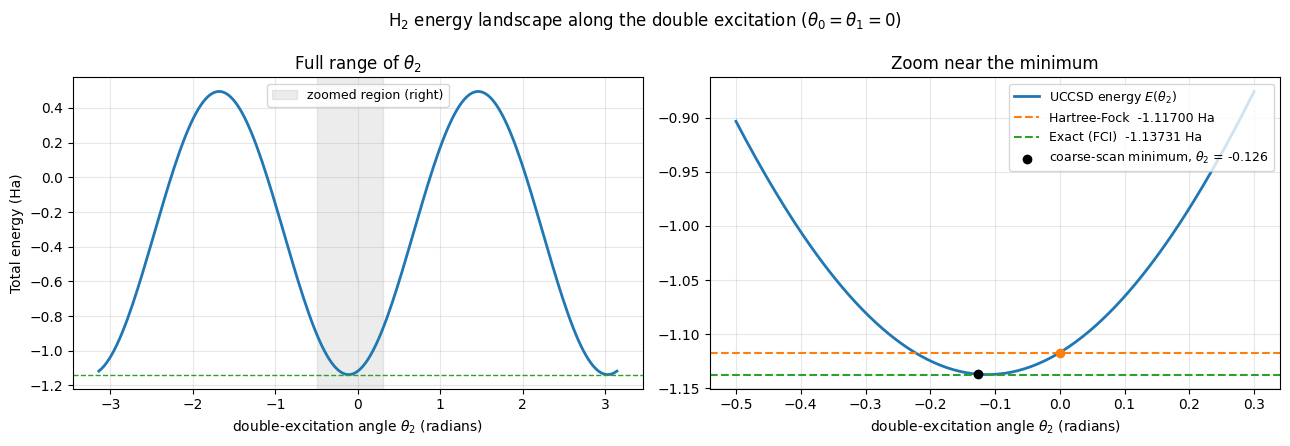

Best scanned energy : -1.136991 Ha at theta_2 = -0.1257 rad
Exact energy        : -1.137306 Ha
Gap (grid-limited)  : 0.3152 mHa


In [12]:
thetas = np.linspace(-np.pi, np.pi, 201)
landscape = [total_energy(ansatz.assign_parameters([0.0, 0.0, t])) for t in thetas]

i_min = int(np.argmin(landscape))
theta2_best, E_scan_best = thetas[i_min], landscape[i_min]

# Zoomed scan near the minimum, finer grid
thetas_zoom = np.linspace(-0.5, 0.3, 161)
landscape_zoom = [total_energy(ansatz.assign_parameters([0.0, 0.0, t])) for t in thetas_zoom]

fig, (ax_full, ax_zoom) = plt.subplots(1, 2, figsize=(13, 4.5))

# Left: the full period, showing the overall shape
ax_full.plot(thetas, landscape, color="tab:blue", lw=2)
ax_full.axhline(E_exact, color="tab:green", ls="--", lw=1)
ax_full.axvspan(-0.5, 0.3, color="grey", alpha=0.15, label="zoomed region (right)")
ax_full.set_title(r"Full range of $\theta_2$")
ax_full.set_xlabel(r"double-excitation angle $\theta_2$ (radians)")
ax_full.set_ylabel("Total energy (Ha)")
ax_full.legend(loc="upper center", fontsize=9)
ax_full.grid(alpha=0.3)

# Right: zoom where HF and exact energies are visibly different (they differ by only ~20 mHa)
ax_zoom.plot(thetas_zoom, landscape_zoom, color="tab:blue", lw=2, label=r"UCCSD energy $E(\theta_2)$")
ax_zoom.axhline(hf_energy, color="tab:orange", ls="--", label=f"Hartree-Fock  {hf_energy:.5f} Ha")
ax_zoom.axhline(E_exact, color="tab:green", ls="--", label=f"Exact (FCI)  {E_exact:.5f} Ha")
ax_zoom.scatter([0.0], [hf_energy], color="tab:orange", zorder=5)
ax_zoom.scatter([theta2_best], [E_scan_best], color="black", zorder=5,
                label=rf"coarse-scan minimum, $\theta_2$ = {theta2_best:.3f}")
ax_zoom.set_title("Zoom near the minimum")
ax_zoom.set_xlabel(r"double-excitation angle $\theta_2$ (radians)")
ax_zoom.legend(loc="upper right", fontsize=9)
ax_zoom.grid(alpha=0.3)

fig.suptitle(r"H$_2$ energy landscape along the double excitation ($\theta_0=\theta_1=0$)")
plt.tight_layout()
plt.show()

print(f"Best scanned energy : {E_scan_best:.6f} Ha at theta_2 = {theta2_best:.4f} rad")
print(f"Exact energy        : {E_exact:.6f} Ha")
print(f"Gap (grid-limited)  : {(E_scan_best - E_exact) * 1000:.4f} mHa")

**Reading the plot**
- **Left panel:** the energy is a smooth sinusoid that repeats every **π**. The double excitation
  rotates the state within a 2-dimensional space spanned by |0101⟩ (HF) and |1010⟩ (both electrons
  excited). Rotating by an extra π only flips the overall sign of the state, which has no physical
  effect, so the two minima are the *same* physical state.
- **Right panel (zoom):** at θ₂ = 0 the curve passes through the **HF energy** (orange dot), as
  expected. Moving to a small **negative** θ₂ lowers the energy down to the **exact line**. A small
  admixture of |1010⟩ is all H₂ needs.
- The curve **never goes below the exact line**, which is the variational principle in action.
- One parameter on a coarse grid already lands within a fraction of a mHa of the exact answer. That
  confirms our ansatz *can* represent the ground state, so the remaining job of VQE is optimisation.

### Phase 2 summary
| Item | Value |
|---|---|
| Ansatz | UCCSD = HF state + 2 single + 1 double excitation |
| Parameters | 3 |
| Hardware cost (transpiled) | 56 CNOTs; full counts and depth printed in section 8 |
| Validation | θ = 0 reproduces HF; matches the Qiskit Nature `UCCSD` class to < 1e-8 Ha |
| Landscape | The minimum along θ₂ reaches the exact energy, so the ansatz is expressive enough |

**Next (Phase 3):** run the real VQE loop. Qiskit's `Estimator` primitive will measure the energy,
and a classical optimizer will tune all 3 angles simultaneously, starting from θ = 0 (Hartree–Fock).